In [1]:
%load_ext autoreload
%autoreload 2
import pandas as pd
import os
import xdas
import importlib
from utils.utils_loc import *
import glob
import subprocess



In [2]:
import matplotlib.cm as cmx
import matplotlib.colors as colors
#from matplotlib.cm import get_cmap
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
import matplotlib
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.ticker as ticker
from obspy import read, UTCDateTime
import os
from obspy.imaging.spectrogram import spectrogram
import matplotlib.patches as patches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.dates as mdates
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = True
plt.rcParams['axes.spines.top'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['axes.grid.axis'] = 'both'
plt.rcParams['grid.color'] = 'darkgrey'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['axes.axisbelow'] = False
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['axes.ymargin'] = 0.1
# -- Ticks and tick labels --
plt.rcParams['axes.edgecolor'] = 'k'
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.width'] = 2
plt.rcParams['xtick.major.size'] = 3
plt.rcParams['ytick.major.size'] = 3
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
# -- Fonts --
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Verdana']
plt.rcParams['text.color'] = 'k'
plt.rcParams['axes.labelcolor'] = 'k'
plt.rcParams['axes.labelsize'] = 12
# -- Saving Options --
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['savefig.transparent'] = False
# -- Plot Styles --
plt.rcParams['lines.linewidth'] = 1
plt.rcParams["lines.markersize"] = 3
plt.rcParams["lines.markeredgewidth"] = 1
plt.rcParams["figure.dpi"] = 300


In [3]:
#Get coords of decimated traces
da = xdas.open_dataarray('traces_DAS/SR_DS_CH2_2025-12-25_14-54-52_UTC.nc')
da = xdas.signal.decimate(da, q = 3, dim = 'distance')
space_deci = xdas.get_sampling_interval(da, dim = 'distance')
print(f"Working with {space_deci}m on the decimated fiber")

Working with 60.0m on the decimated fiber


C:\Users\franc\AppData\Local\Temp\ipykernel_24032\1215431006.py:4: FutureWarning: coordinate 'distance' has no declared sampling interval; inferred 60.0 (accepting jitter up to tolerance=2.9103830456733704e-11). This implicit inference is deprecated and will raise in a future release; make the coordinate regular with `da['distance'] = da['distance'].to_regular(tolerance=...)`, or open the files with a tolerance
  space_deci = xdas.get_sampling_interval(da, dim = 'distance')


# DEFINE EVENT INDEX

In [4]:
idx = '17933b'
reference_location = {'lat': 40.674, 'lon': 15.618, 'dep': 13.6}

# CREATE THE HYP FILE FOR NLLoc

In [6]:
folder_out = 'results/obs'
add_isnet = False

os.makedirs(folder_out, exist_ok=True)

with open(f"{folder_out}/{idx}_picks.hyp", 'w') as fout:
    df = pd.read_csv(f"results/gamma_PN_DAS_local_picks/event.txt")
    for i in range(df.shape[0]):
        if df["OFFSET"][i] in da["distance"].values:
                date = str(df["TIME"][i]).split(' ')[0]
                time = str(df["TIME"][i]).split(' ')[1]
                year = date.split('-')[0][-2:]
                month = date.split('-')[1]
                day = date.split('-')[-1]
                hour = time[:11].replace(':','').replace('+','.')
                phase = df["PHASE"][i].upper()
                station = f"{5000 + int(df['ID_OLD'][i]):04}"
                weight = 1 #prob2weights(df["PROB"][i])
                fout.write(f"{station}I{phase} {weight} {year}{month}{day}{hour}\n")
    if add_isnet:
        with open(f"utils/picks_isnet/{idx}.hypo.arc.in", 'r') as fout2:
            f = fout2.readlines()
        for line in f[1:]:
            if 'IP' in line:
                fout.write(f"{line[:4]}{line[13:17]} {line[19:34]}\n")
            if 'IS' in line:
                fout.write(f"{line[:4]}{line[46:50]} {line[19:29]}{line[41:46]}\n")

# RUN NLLoc

In [ ]:
print("Locating event! This can take some minutes...")

os.makedirs(f"results/location_results/{idx}", exist_ok=True)
# Convert the current Windows directory to a WSL-compatible path
windows_dir = os.getcwd()
wsl_dir = "/mnt/" + windows_dir[0].lower() + windows_dir[2:].replace("\\", "/")
 
command = f"cd '{wsl_dir}' && ./NLLoc/src/NLLoc ./NLLoc/run_punto_medio/ISNet_nll.run"
 
result = subprocess.run(
    ["wsl", "bash", "-lc", command],
    capture_output=True,
    text=True
)
 
print("Return code:", result.returncode)
print("STDOUT:", result.stdout)
print("STDERR:", result.stderr)

# VISUALIZE LOCATION RESULTS

918 picks
613 channels
ISNet location: Lat 40.6900 Lon 15.4280 Dep 14.7 km
Fiber location: Lat 40.7264 Lon 15.4285 Dep 11.9 km


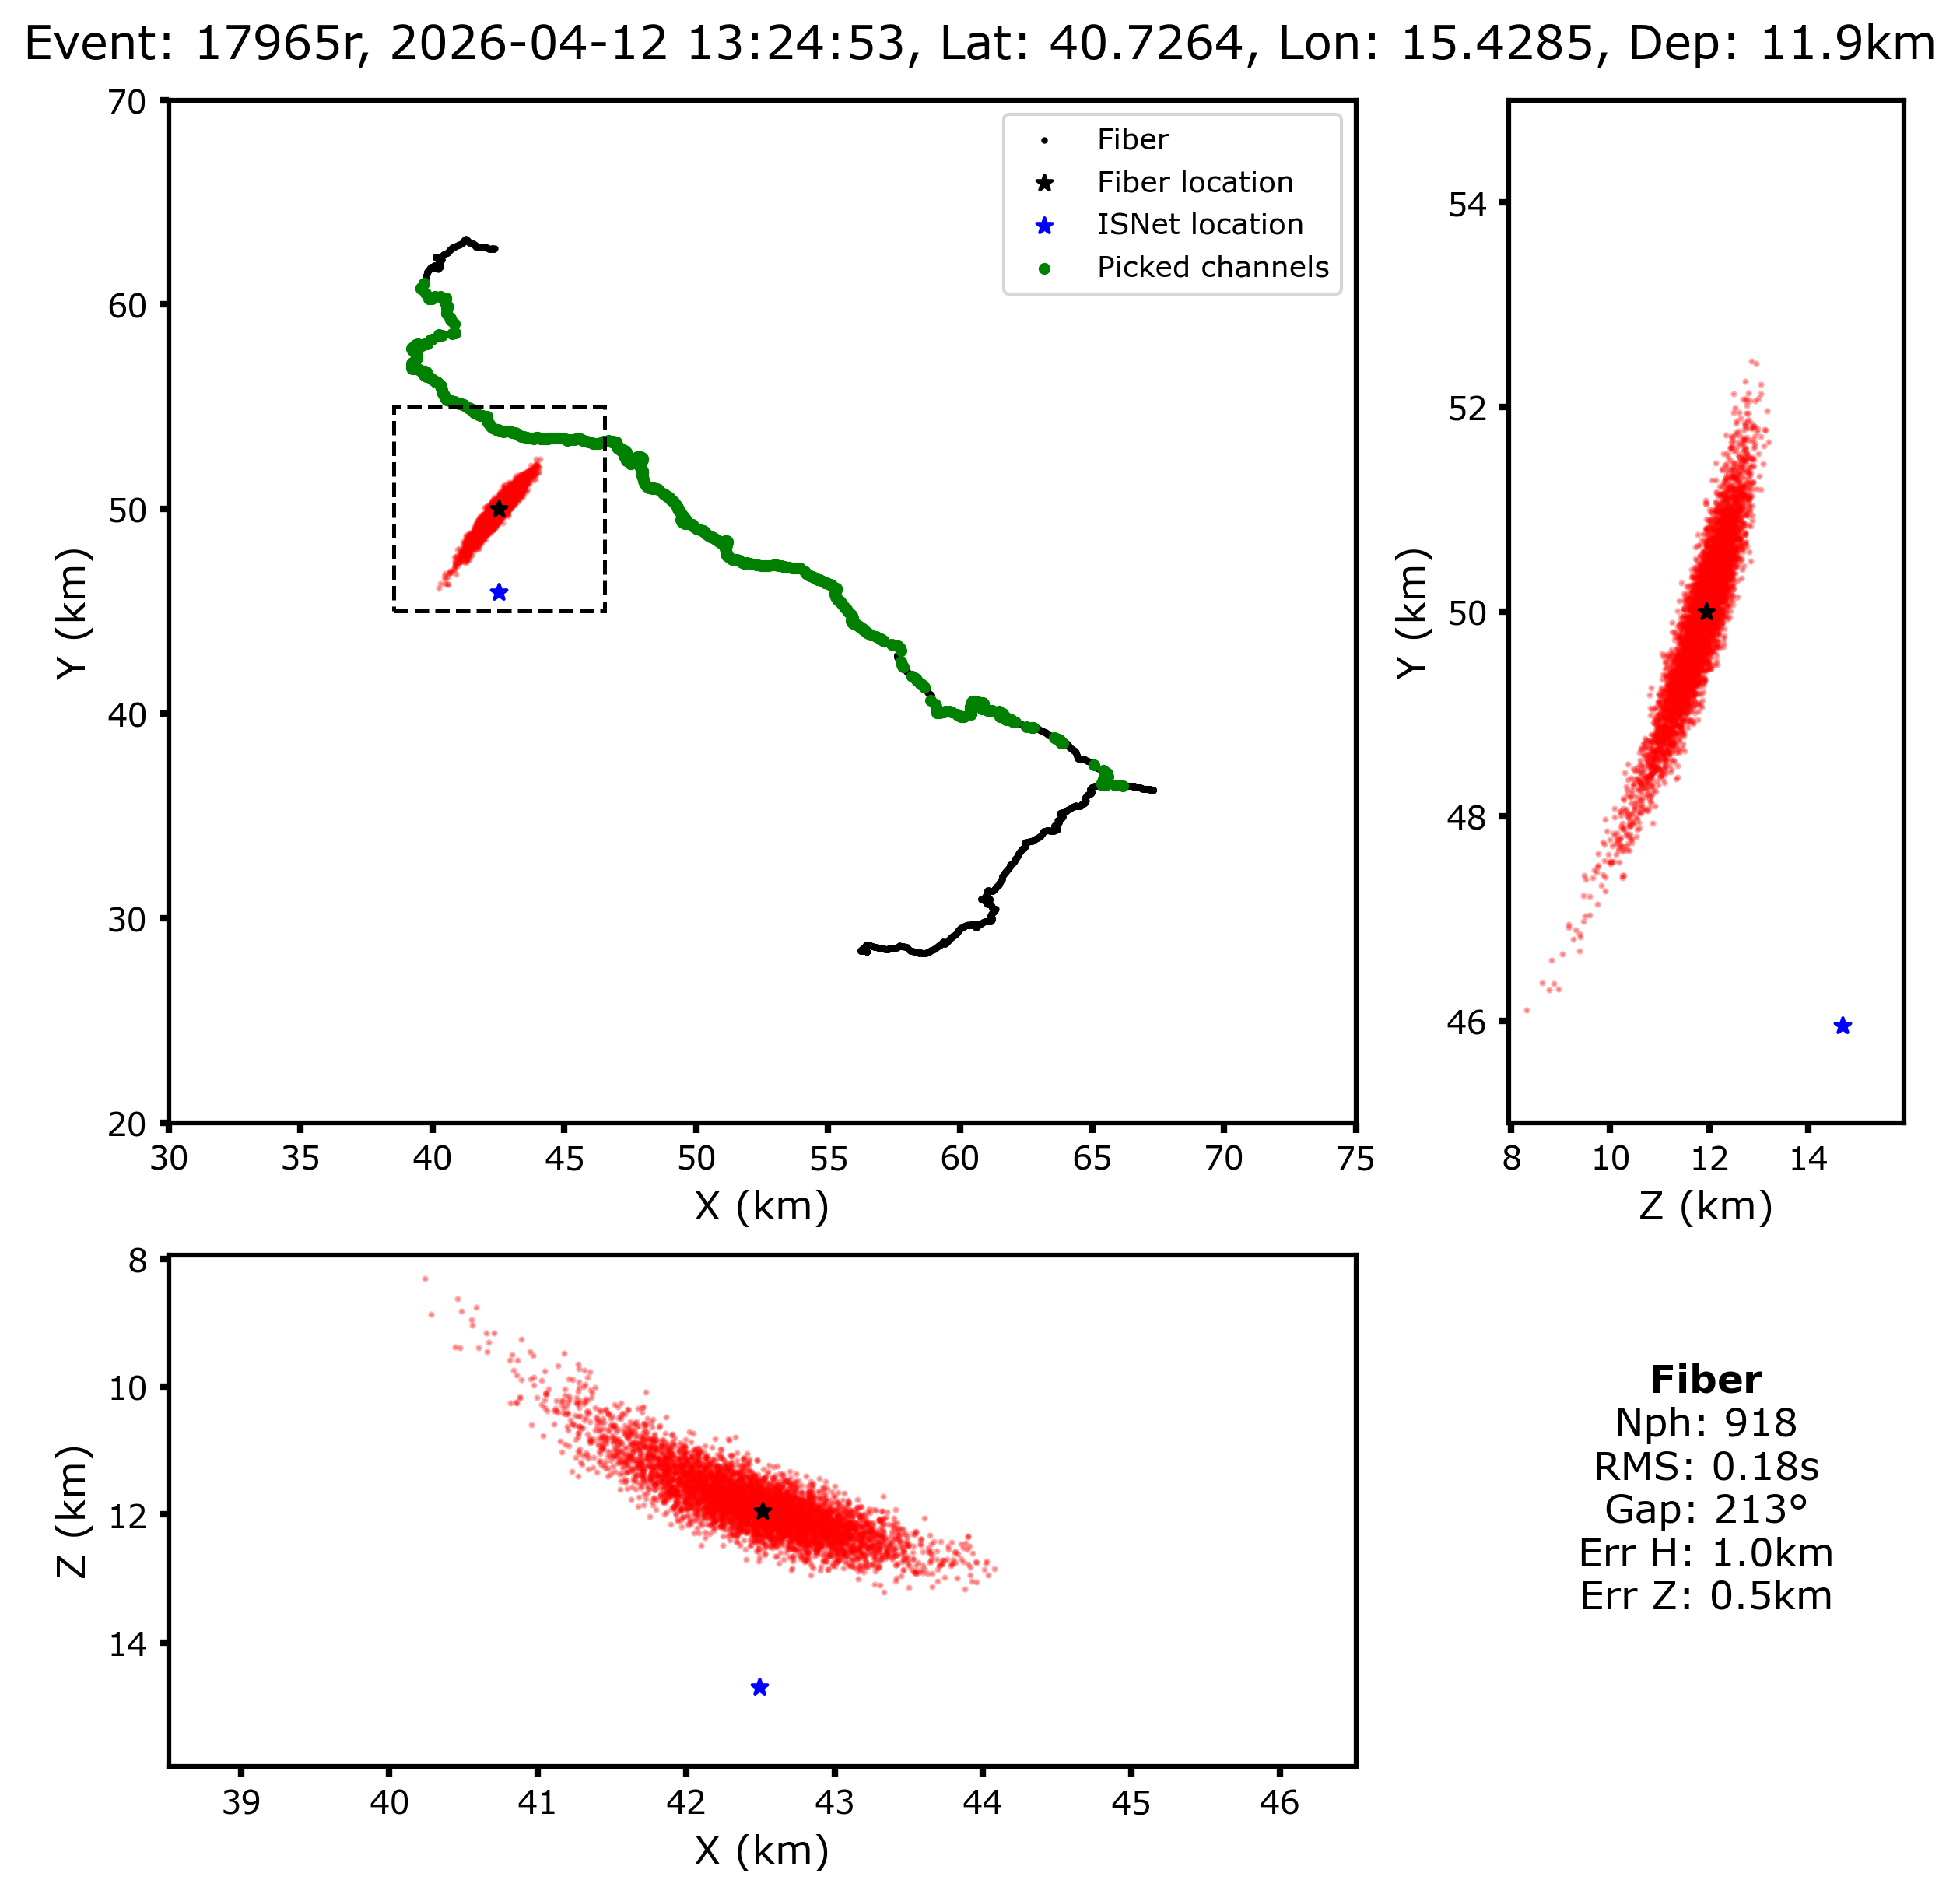

In [11]:
figure_path = 'results/location_results'
os.makedirs(figure_path, exist_ok = True)

files = glob.glob(f"results/location_results/{idx}/PhaseNet.1*.hyp")

for file in files:
    #event_code = "loc_fiber_deci/PhaseNet.19260610.073146.grid0.loc"
    event_code = file[:-4]

    #Read scatter file
    filename = f"{event_code}.scat" #filename = "loc_fiber/PhaseNet.19260811.094910.grid0.loc.scat"
    scatter = get_scatter(filename)

    #read cable coordinates
    stations = pd.read_csv('utils/cable_location.txt', header = None, delimiter = '\s+')
    stations.columns = ['id','x', 'y', 'z']

    #get picked stations
    picked_stations = get_picked_stations(event_code, stations)

    #get location
    location_file = f"{event_code}.hyp"
    location, quality = get_location(location_file, get_id = False)
    location["id"] = idx
    local_isnet_location = latlon_to_local(reference_location["lat"], reference_location["lon"])
    isnet_location = {'x': local_isnet_location[0], 'y': local_isnet_location[1],  'z': reference_location["dep"]}
    print(f"ISNet location: Lat {reference_location['lat']:.4f} Lon {reference_location['lon']:.4f} Dep {reference_location['dep']:.1f} km")
    print(f"Fiber location: Lat {location['lat']:.4f} Lon {location['lon']:.4f} Dep {location['dep']:.1f} km")

    couples = ['xy', 'xz', 'zy']
    #limits = {'x': [52,61], 'y': [40,49], 'z': [2,7]}
    limits = {'x': [location["x"] - 4, location["x"] + 4], 'y': [location["y"] - 5, location["y"] + 5], 'z': [location["z"] - 4, location["z"] + 4]}

    fig = plot_mosaic(couples, stations, picked_stations, location, isnet_location, quality, limits, scatter)
    fig.savefig(f"{figure_path}/{location['id']}/{location['id']}.png")

